# Question 1 (18 pts) 
We will look into the NYC flights dataset using Pandas!

## Question 1.1 (2 pts)
Load the dataset from flights.csv file given with this file into a dataframe variable named `df`

In [52]:
import pandas as pd
df = pd.read_csv('flights.csv')

In [53]:
assert df is not None
assert isinstance(df, pd.core.frame.DataFrame)

## Question 1.2 (2 pts)
Get the total count of flights for each month and display the top three months with the highest count.

In [54]:
df.head(3)

,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400.0,5.0,15.0,1.357034e+09
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416.0,5.0,29.0,1.357034e+09
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089.0,5.0,40.0,1.357034e+09


In [55]:
df[['month', 'flight']].groupby('month').count().sort_values('flight', ascending = False)


,flight
month,
7,29425
8,29327
10,28889
3,28834
5,28796
4,28330
6,28243
12,28135
9,27574


In [56]:
monthly_count = df['month'].value_counts().sort_values(ascending = False).head(3)

In [57]:
assert all(monthly_count == pd.Series([29425, 29327, 28889], index = [7, 8, 10]))

## Question 1.3 (2 pts)
First get a new dataframe with the three columns of interest 'carrier', 'month' and 'dep_delay'. Then compute the average dep_delay for each carrier and for each month. Rank the departure delays/month and filter the 1st rank carrier for each month (carrier with the lowest dep_delay for the month will get the 1st rank). Show the results in ascending order of the month

Hint: Some of the functions that can help are rank(), unstack(), stack(). 

In [58]:
df.head(3)

,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400.0,5.0,15.0,1.357034e+09
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416.0,5.0,29.0,1.357034e+09
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089.0,5.0,40.0,1.357034e+09


In [59]:
delay_avg = df[['carrier', 'month', 'dep_delay']].groupby(['month', 'carrier']).mean() #average delay
delay_avg['rank'] = delay_avg.groupby('month').rank() #rank delay within each month
delay_avg[delay_avg['rank'] == 1].sort_values('month')
# delay_avg[0:45]

,,dep_delay,rank
month,carrier,,
1,VX,1.063492,1.0
2,AS,0.722222,1.0
3,HA,1.161290,1.0
4,HA,-2.100000,1.0
5,HA,-1.451613,1.0
6,HA,1.466667,1.0
7,HA,-1.709677,1.0
8,HA,1.677419,1.0
9,HA,-5.440000,1.0


In [60]:

df_new = df[['carrier', 'month', 'dep_delay']]
delay_avg = df_new.groupby(['month', 'carrier']).mean() #average delay
delay_avg['rank'] = delay_avg.groupby('month').rank() #rank delay within each month

avg_delay = delay_avg[delay_avg['rank'] == 1].sort_values('month')

In [61]:
# Hidden test here

## Question 1.4 (2 pts)
Find the 5 top destinations in this dataset (most number of flights to). Filter only those flights to these top 5 destinations and then show the distribution of carriers on this filtered data.

In [62]:
df.head(3)

,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400.0,5.0,15.0,1.357034e+09
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416.0,5.0,29.0,1.357034e+09
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089.0,5.0,40.0,1.357034e+09


In [63]:
top_dest = df['dest'].value_counts().sort_values(ascending = False).head(5).index.tolist()
top_carrier_count = df[df['dest'].isin(top_dest)]['carrier'].value_counts().sort_values(ascending = False)

In [64]:
import numpy as np
assert np.all(top_dest == np.array(['ORD', 'ATL', 'LAX', 'BOS', 'MCO']))

## Question 1.5 (2 pts)
Get the total count of cancelled flights in this dataset. We'll say that a cancelled flight has dep_time missing.

In [65]:
cancelled_flight_count = len(df[df['dep_time'].isna()])

In [66]:
assert cancelled_flight_count == 8255

## Question 1.6 (2 pts)
Count all the destinations that have a letter 'K' anywhere in the name code.

In [67]:
dest_with_k = len(df[df['dest'].str.contains('K', na = False)])

In [68]:
assert dest_with_k == 4589

## Question 1.7 (2 pts)
Create a new column called speed that computes the speed as distance/air_time

In [69]:
df['speed'] = df['distance']/df['air_time']

In [70]:
assert type(df['speed']) == pd.Series 
assert abs(df['speed'][0] - 6.1674) < 1

## Question 1.8 (4 pts)
Segment the dep_time 24 hours into 
* night from 12 midnight to 5 am
* morning from 5:01 am to 12 noon
* afternoon from 12.01 noon to 5 pm
* evening from 5.01 pm to 12 am

And then run a query to find the total flights in each segment and save that value in the given variable.


In [71]:
df.head(3)

,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour,speed
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400.0,5.0,15.0,1.357034e+09,6.167401
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416.0,5.0,29.0,1.357034e+09,6.237885
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089.0,5.0,40.0,1.357034e+09,6.806250


<Axes: >

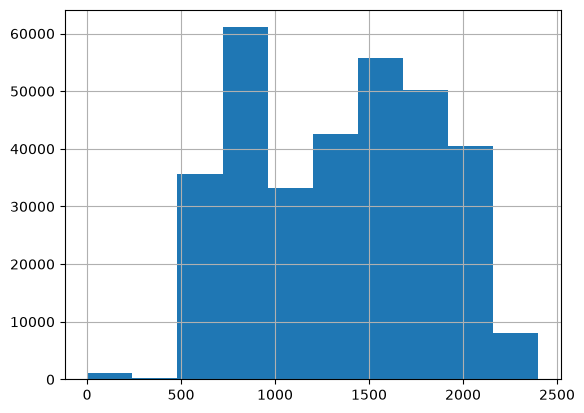

In [72]:
df['dep_time'].hist()

In [73]:
df['part_of_day'] = None
df.loc[df['dep_time'] <= 500, 'part_of_day'] = "night"
df.loc[(df['dep_time'] > 500) & (df['dep_time'] <= 1200), 'part_of_day'] = "morning"
df.loc[(df['dep_time'] > 1200) & (df['dep_time'] <= 1700), 'part_of_day'] = "afternoon"
df.loc[(df['dep_time'] > 1700) & (df['dep_time'] <= 2400), 'part_of_day'] = "evening"
df['part_of_day'].value_counts()

part_of_day
morning      129939
afternoon     98733
evening       98362
night          1487
Name: count, dtype: int64

In [74]:
parts_of_day_count = df['part_of_day'].value_counts(ascending = False)

In [75]:
assert parts_of_day_count['morning'] == 129939
assert parts_of_day_count['evening'] == 98362

# Question 2 (9 pts) 
In this problem, we will do some exploratory data analytics (EDA) by using some of the visualization libraries in Python.

In [76]:
import numpy as np
import pandas as pd
import seaborn as sns
flights = pd.read_csv("flights.csv")
airports = pd.read_csv("airports.csv")
flights.describe()

,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,flight,air_time,distance,hour,minute,time_hour
count,336776.0,336776.000000,336776.000000,328521.000000,336776.000000,328521.000000,328063.000000,336776.000000,327346.000000,336776.000000,327346.000000,336776.000000,336776.000000,336776.000000,3.367760e+05
mean,2013.0,6.548510,15.710787,1349.109947,1344.254840,12.639070,1502.054999,1536.380220,6.895377,1971.923620,150.686460,1039.912604,13.180247,26.230100,1.372843e+09
std,0.0,3.414457,8.768607,488.281791,467.335756,40.210061,533.264132,497.457142,44.633292,1632.471938,93.688305,733.233033,4.661316,19.300846,9.009993e+06
min,2013.0,1.000000,1.000000,1.000000,106.000000,-43.000000,1.000000,1.000000,-86.000000,1.000000,20.000000,17.000000,1.000000,0.000000,1.357034e+09
25%,2013.0,4.000000,8.000000,907.000000,906.000000,-5.000000,1104.000000,1124.000000,-17.000000,553.000000,82.000000,502.000000,9.000000,8.000000,1.365095e+09
50%,2013.0,7.000000,16.000000,1401.000000,1359.000000,-2.000000,1535.000000,1556.000000,-5.000000,1496.000000,129.000000,872.000000,13.000000,29.000000,1.372860e+09
75%,2013.0,10.000000,23.000000,1744.000000,1729.000000,11.000000,1940.000000,1945.000000,14.000000,3465.000000,192.000000,1389.000000,17.000000,44.000000,1.380625e+09
max,2013.0,12.000000,31.000000,2400.000000,2359.000000,1301.000000,2400.000000,2359.000000,1272.000000,8500.000000,695.000000,4983.000000,23.000000,59.000000,1.388549e+09


## Question 2.1 (3 pts)

Line charts are ideal to show a trend line. Draw a line chart to show monthly frequency count of flights as a trend line for the year 2013. Be sure to choose the correct data to display on the x-axis and y-axis.

[Text(0.5, 1.0, 'Monthly breakdown'),
 Text(0.5, 0, 'Months (1-12)'),
 Text(0, 0.5, 'Monthly Frequency')]

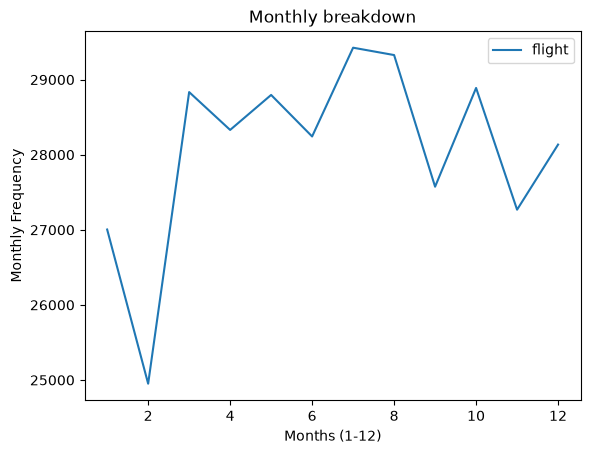

In [77]:
monthly_count = flights[flights['year']==2013][["month", "flight"]].groupby("month").count().sort_values("month")
fig1 = sns.lineplot(data = monthly_count)
fig1.set(title = "Monthly breakdown",
         xlabel = "Months (1-12)",
         ylabel = "Monthly Frequency")

In [78]:
assert fig1.get_title() == 'Monthly breakdown'
assert fig1.get_xlabel() == 'Months (1-12)'
assert fig1.get_ylabel() == 'Monthly Frequency'
assert dict(fig1.lines[0].get_xydata())[6] == 28243

## Question 2.2 (3 pts)
Show the top 5 airports that people flew into using a bar chart. 

In [79]:
top_5_dest = flights["dest"].value_counts().sort_values(ascending=False)[:5]

[Text(0.5, 1.0, 'Top 5 airports that people flew into'),
 Text(0.5, 0, 'Airport codes'),
 Text(0, 0.5, 'Total arrivals')]

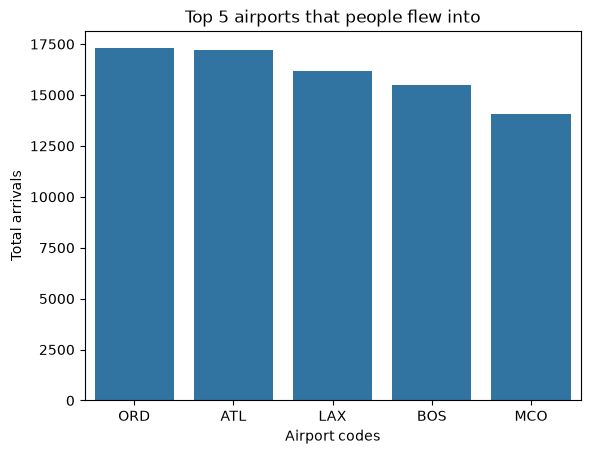

In [80]:
fig_2 = sns.barplot(data = top_5_dest)
fig_2.set(title = "Top 5 airports that people flew into",
         xlabel = "Airport codes",
         ylabel = "Total arrivals")

In [81]:
x_axis = fig_2.get_xaxis()
text1 = x_axis.get_ticklabels()[0]
assert text1.get_text() == 'ORD'
assert fig_2.get_title() == 'Top 5 airports that people flew into'
assert fig_2.get_xlabel() == 'Airport codes'
assert fig_2.get_ylabel() == 'Total arrivals'

## Question 2.3 (3 pts)

Segment the flights based on time-slots with the following criteria
* flights that depart from 00-5:59am as 'red-eye' flights
* flights that depart from 6am - 11:59am as 'morning'
* flights that depart from 12noon - 3:59pm as 'afternoon'
* flights that depart from 4pm - 11:59pm as 'evening' 

And using seaborn create a plot as shown below. PS: Feel free to choose your color palette.

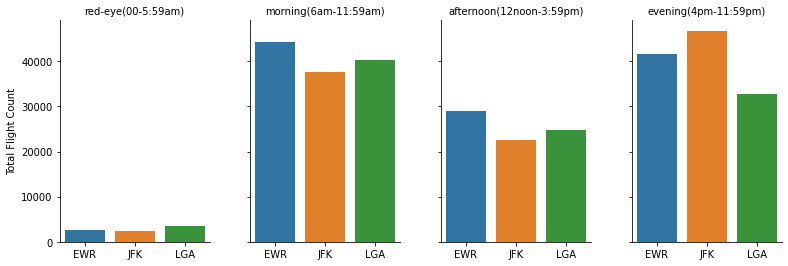

In [98]:
flights['origin'].value_counts()

origin
EWR    120835
JFK    111279
LGA    104662
Name: count, dtype: int64

In [84]:
flights['part_of_day'] = None
flights.loc[df['dep_time'] <= 559, 'part_of_day'] = "red-eye"
flights.loc[(df['dep_time'] > 559) & (flights['dep_time'] <= 1159), 'part_of_day'] = "morning"
flights.loc[(df['dep_time'] > 1159) & (flights['dep_time'] <= 1659), 'part_of_day'] = "afternoon"
flights.loc[(df['dep_time'] > 1659) & (flights['dep_time'] <= 2359), 'part_of_day'] = "evening"
flights.head(3)

,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour,part_of_day
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400.0,5.0,15.0,1.357034e+09,red-eye
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416.0,5.0,29.0,1.357034e+09,red-eye
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089.0,5.0,40.0,1.357034e+09,red-eye


/tmp/ipykernel_29949/2696731476.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  fig_3 = sns.catplot(data = flights,


Text(-13.555555555555541, 0.5, 'Flight Count')

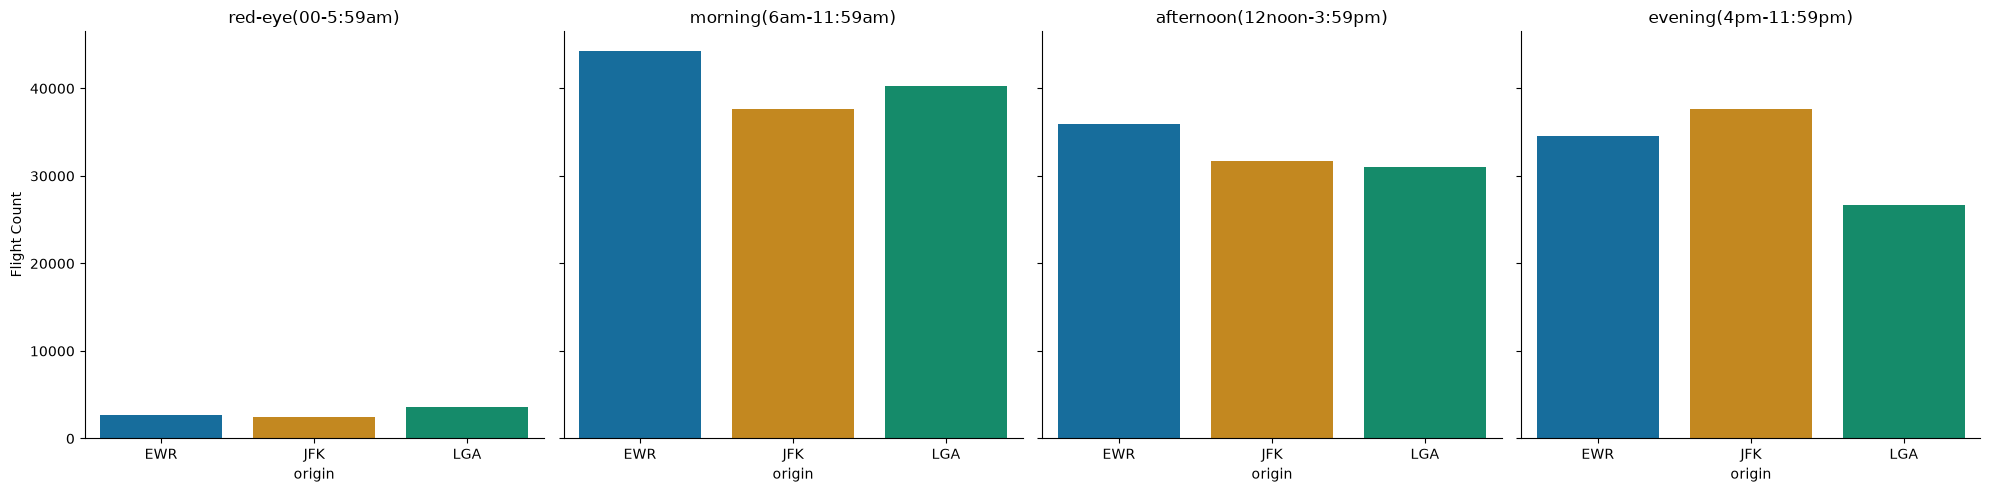

In [113]:
fig_3 = sns.catplot(data = flights,
                    x = "origin",
                    col = "part_of_day",
                    kind = "count",
                    order = ["EWR", "JFK", "LGA"],
                    col_order = ["red-eye", "morning", "afternoon", "evening"],
                    palette = "colorblind")

fig_3.axes[0,0].set_title("red-eye(00-5:59am)")
fig_3.axes[0,1].set_title("morning(6am-11:59am)")
fig_3.axes[0,2].set_title("afternoon(12noon-3:59pm)")
fig_3.axes[0,3].set_title("evening(4pm-11:59pm)")
fig_3.axes[0,0].set_ylabel("Flight Count")

In [114]:
assert fig_3.figure.get_axes()[0].get_title() == 'red-eye(00-5:59am)'
assert fig_3.figure.get_axes()[0].get_ylabel() == 'Flight Count'
assert fig_3.figure.get_axes()[1].get_title() == 'morning(6am-11:59am)'